# Linear Regression met SciKit-Learn - oplossing

We zagen hoe we een zeer eenvoudige beste fit-lijn konden creëren, maar laten we nu ons toolbox aanzienlijk uitbreiden om te beginnen nadenken over de overwegingen van overfitting, underfitting, model-evaluatie, en ook meerdere kenmerken!

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data


Deze voorbeeldgegevens tonen de verkoop (in duizenden eenheden) voor een bepaald product in functie van reclamebudgetten (in duizenden dollars) voor TV, radio en krantenmedia.

Lees de data (Advertising.csv) in en bekijk de eerste rijen.

In [2]:
df = pd.read_csv("Advertising.csv")

In [3]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## Meervoudige lineaire regressie

### Uitbreiding

Voorheen hebben we nagegaan of er een relatie is tussen de total spend en de sales.  NU willen we de invloed van elk advertentiekanaal apart meten.  

Start met de onderlinge relatie tussen de verschillende advertentiekanalen te visualiseren.

### Multiple Features (N-Dimensional)

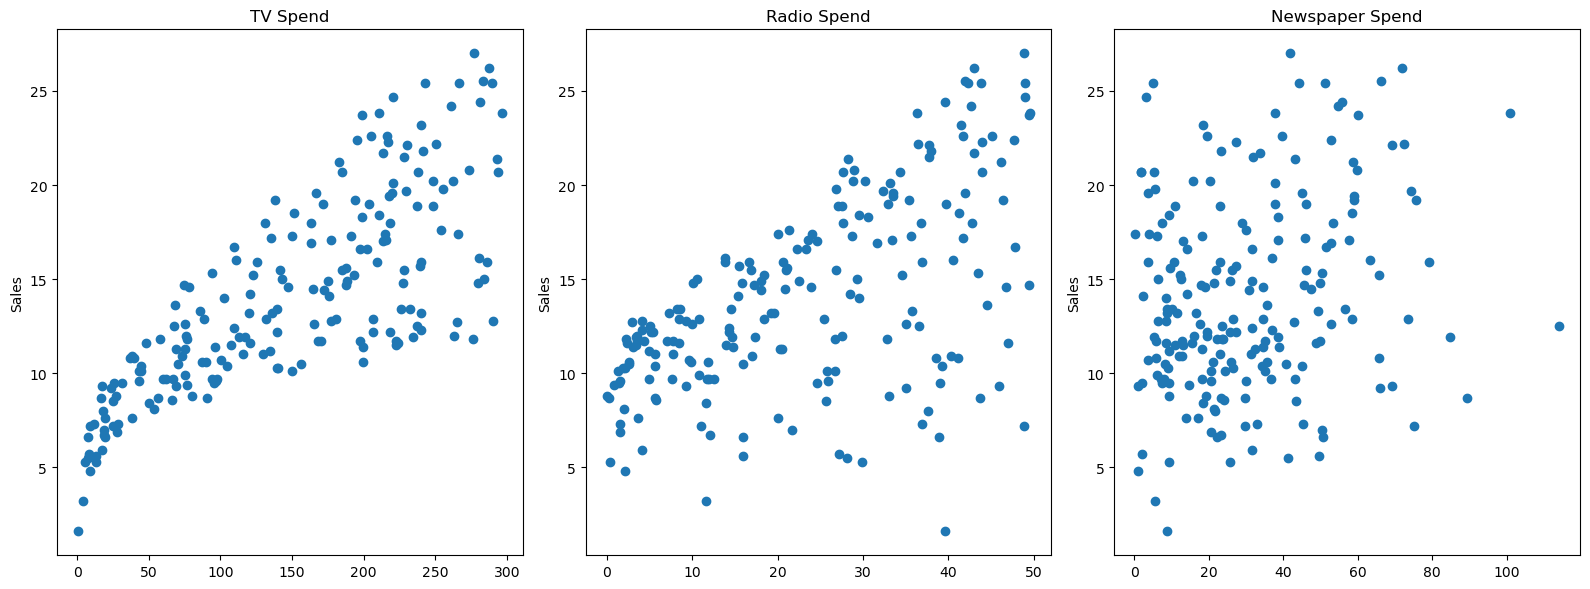

In [5]:
# relatie tussen de features...
fig,axes = plt.subplots(nrows=1,ncols=3,figsize=(16,6))

axes[0].plot(df['TV'],df['sales'],'o')
axes[0].set_ylabel("Sales")
axes[0].set_title("TV Spend")

axes[1].plot(df['radio'],df['sales'],'o')
axes[1].set_title("Radio Spend")
axes[1].set_ylabel("Sales")

axes[2].plot(df['newspaper'],df['sales'],'o')
axes[2].set_title("Newspaper Spend");
axes[2].set_ylabel("Sales")
plt.tight_layout();

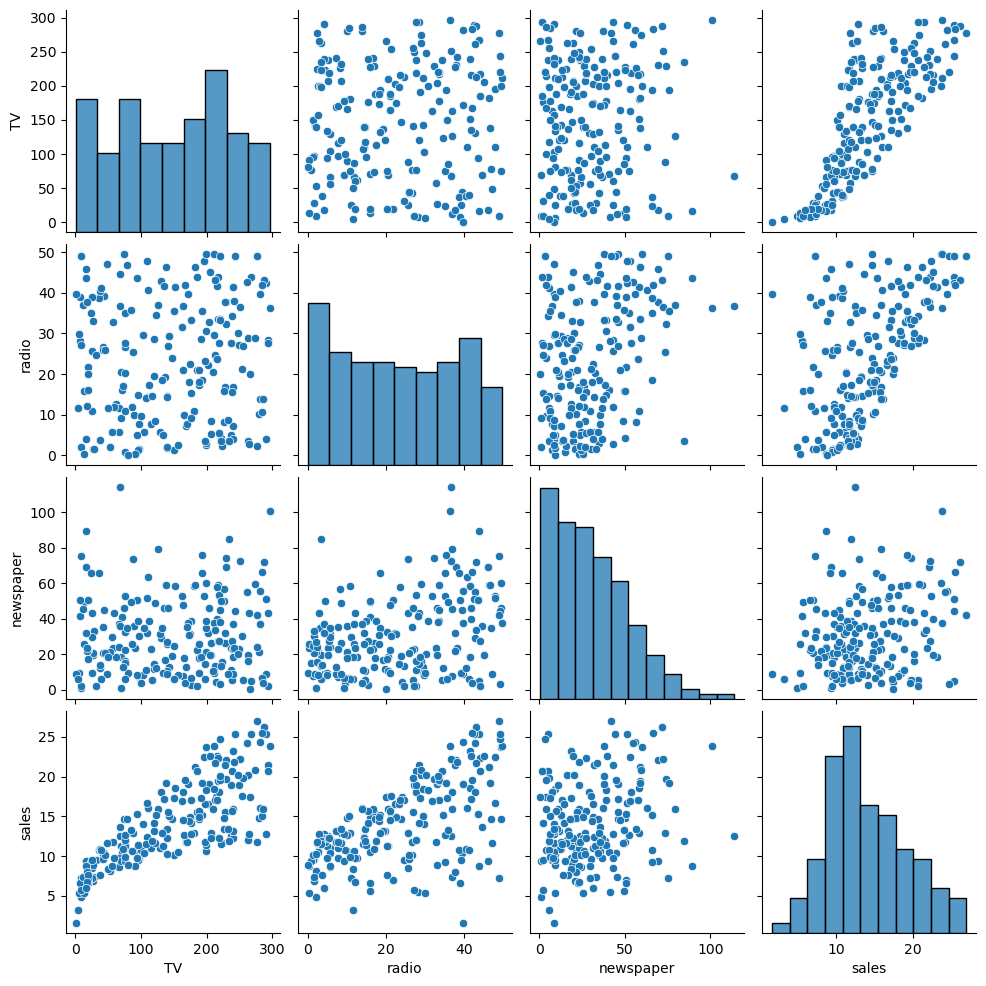

In [6]:
# alternatief
sns.pairplot(df,diag_kind='hist')

### Splits de dataset op in features X en targets y

In [7]:
X = df.drop('sales',axis=1)
y = df['sales']

### Train | Test Split

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [10]:
# Ga na hoeveel items er in de initiële dataset zitten, 
# en hoeveel er in de train en test set zitten.
print(len(X_train))
print(len(X_test))
print(len(y_train))
print(len(y_test))

140
60
140
60


## Maken van het model (de Estimator)

#### Importeer de model class van de model family

In [11]:
from sklearn.linear_model import LinearRegression

#### Maak een instantie van het model met de parameters

In [12]:
model = LinearRegression()

### Fit/Train het Model op de training data

**Enkel op de training data fitten om een eerlijke evaluatie van de performantie later mogelijk te maken!**

In [13]:
model.fit(X_train,y_train)

LinearRegression()

### Voorspel nu de sales waarden voor de test set

In [14]:
test_predictions = model.predict(X_test)

In [15]:
test_predictions

array([15.74131332, 19.61062568, 11.44888935, 17.00819787,  9.17285676,
        7.01248287, 20.28992463, 17.29953992,  9.77584467, 19.22194224,
       12.40503154, 13.89234998, 13.72541098, 21.28794031, 18.42456638,
        9.98198406, 15.55228966,  7.68913693,  7.55614992, 20.40311209,
        7.79215204, 18.24214098, 24.68631904, 22.82199068,  7.97962085,
       12.65207264, 21.46925937,  8.05228573, 12.42315981, 12.50719678,
       10.77757812, 19.24460093, 10.070269  ,  6.70779999, 17.31492147,
        7.76764327,  9.25393336,  8.27834697, 10.58105585, 10.63591128,
       13.01002595,  9.77192057, 10.21469861,  8.04572042, 11.5671075 ,
       10.08368001,  8.99806574, 16.25388914, 13.23942315, 20.81493419,
       12.49727439, 13.96615898, 17.56285075, 11.14537013, 12.56261468,
        5.50870279, 23.29465134, 12.62409688, 18.77399978, 15.18785675])

In [16]:
# Importeer de performance metrics van sklearn (MAE, MSE, RMSE)

In [17]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [18]:
MAE = mean_absolute_error(y_test,test_predictions)
MSE = mean_squared_error(y_test,test_predictions)
RMSE = np.sqrt(MSE)

In [19]:
print(MAE)
print(MSE)
print(RMSE)

1.2137457736144803
2.298716697886377
1.5161519375993875


In [20]:
# we willen deze resultaten vergelijken met het gemiddelde van de dataset:
df['sales'].mean()

14.0225

#### Is dit resultaat goed?

In [58]:
from sklearn.metrics import r2_score

In [59]:
r2 = r2_score(y_test, test_predictions)
print(f'r2 score = {r2}')

r2 score = 0.9185780903322446


De determinatiecoëfficiënt R² zegt hoeveel van de variabiliteit verklaard wordt door het model.  Bij perfecte voorspellingen is R² = 1.  Een negatieve waarde voor R² zegt dat het model slechter scoort dan een horizontale lijn y = y_bar

## Residuals

### We checken eerst even de residuals voor de **geschikte** dataset:

In [21]:
quartet = pd.read_csv('anscombes_quartet1.csv')

We weten dat de regressiefunctie voor elke dataset in anscombes quartes gelijk is aan: y = 3.00 + 0.500x
Uit deze functie kunnen we zowel de voorspelde waarde ŷ als de residuals (y - ŷ) halen:

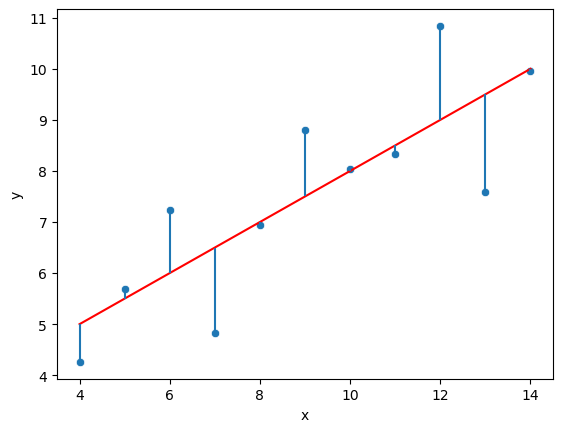

In [22]:
quartet['pred_y'] = 3 + 0.5 * quartet['x']
quartet['residual'] = quartet['y'] - quartet['pred_y']

# plot de ruwe data
sns.scatterplot(data=quartet,x='x',y='y')
# plot de regressielijn
sns.lineplot(data=quartet,x='x',y='pred_y',color='red')
# plot de verticale lijnen tussen de punten en de regressielijn
plt.vlines(quartet['x'],quartet['y'],quartet['y']-quartet['residual'])

<Axes: xlabel='residual', ylabel='Density'>

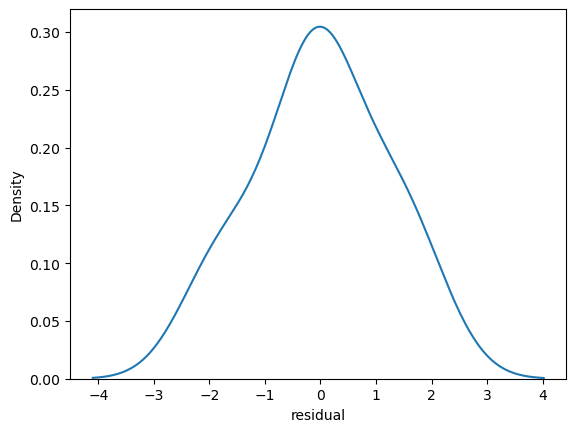

In [23]:
# Check of deze data normaal verdeeld is:

# De sns.kdeplot functie maakt deel uit van de Seaborn-bibliotheek in Python en wordt gebruikt om Kernel Density Estimation (KDE) plots te maken. 
# KDE is een manier om de kansdichtheidsfunctie van een continue willekeurige variabele te schatten. 
# Eenvoudig gezegd, het biedt een meer gladgestreken versie van een histogram en streeft ernaar om de onderliggende "echte" verdeling van de gegevens te benaderen.

sns.kdeplot(quartet['residual'])

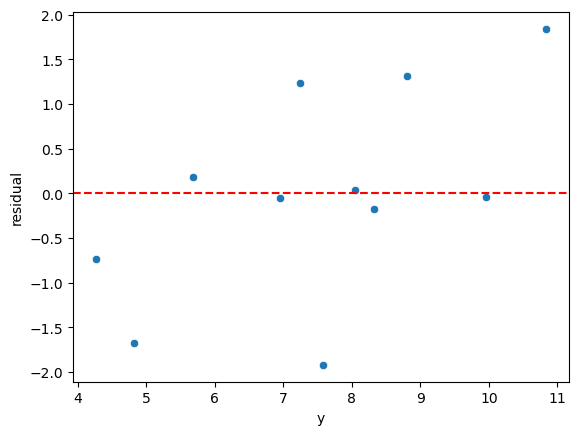

In [24]:
# Plot de residuals tov de werkelijke y-waarden.  Is er een patroon te herkennen? 

sns.scatterplot(data=quartet,x='y',y='residual')
# voeg een horizontale lijn toe
plt.axhline(y=0, color='r', linestyle='--')

### Check nu zelf de residuals voor de **niet geschikte** datasets:

In [25]:
# Analyseer nu de residuals voor de niet geschikte datasets:
quartet = pd.read_csv('anscombes_quartet2.csv')

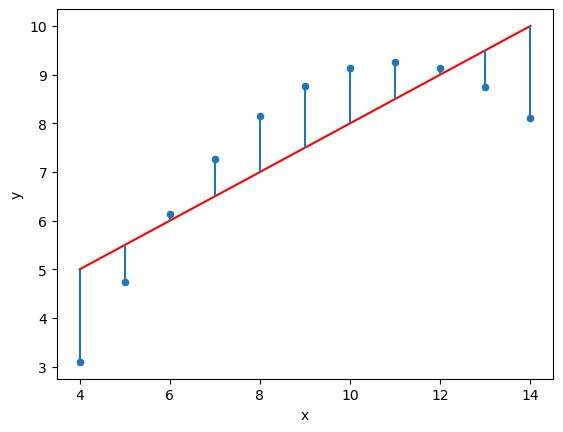

In [26]:
# y = 3.00 + 0.500x
quartet['pred_y'] = 3 + 0.5 * quartet['x']
quartet['residual'] = quartet['y'] - quartet['pred_y']

sns.scatterplot(data=quartet,x='x',y='y')
sns.lineplot(data=quartet,x='x',y='pred_y',color='red')
plt.vlines(quartet['x'],quartet['y'],quartet['y']-quartet['residual'])

<Axes: xlabel='residual', ylabel='Density'>

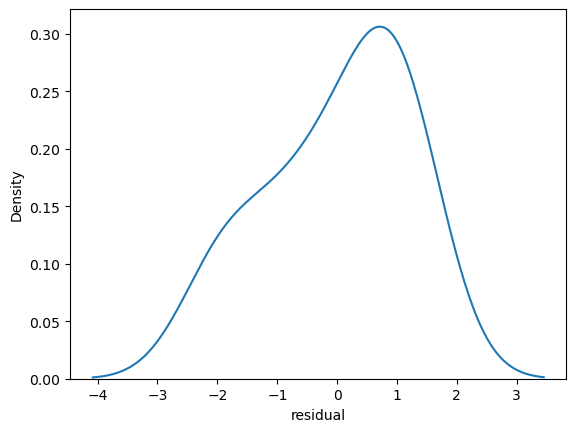

In [27]:
sns.kdeplot(quartet['residual'])

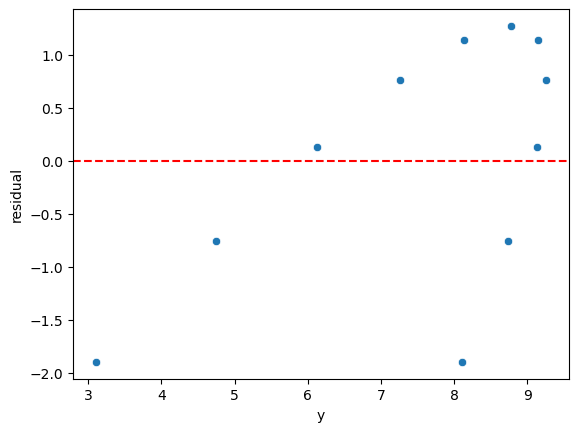

In [28]:
sns.scatterplot(data=quartet,x='y',y='residual')
plt.axhline(y=0, color='r', linestyle='--')

### En de laatste:

In [29]:
quartet = pd.read_csv('anscombes_quartet4.csv')

In [30]:
quartet

,x,y
0,8.0,6.58
1,8.0,5.76
2,8.0,7.71
3,8.0,8.84
4,8.0,8.47
5,8.0,7.04
6,8.0,5.25
7,19.0,12.50
8,8.0,5.56
9,8.0,7.91


In [31]:
# y = 3.00 + 0.500x
quartet['pred_y'] = 3 + 0.5 * quartet['x']

In [32]:
quartet['residual'] = quartet['y'] - quartet['pred_y']

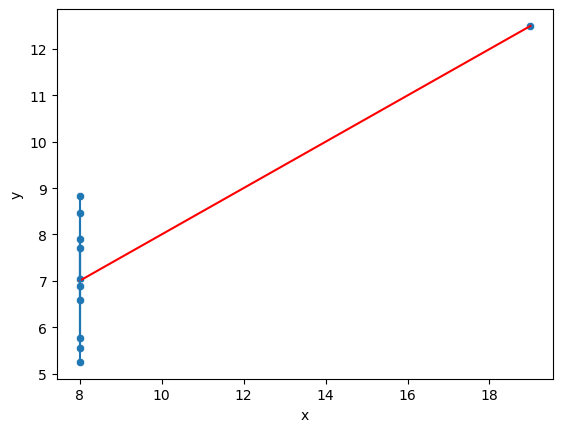

In [33]:
sns.scatterplot(data=quartet,x='x',y='y')
sns.lineplot(data=quartet,x='x',y='pred_y',color='red')
plt.vlines(quartet['x'],quartet['y'],quartet['y']-quartet['residual'])

<Axes: xlabel='residual', ylabel='Density'>

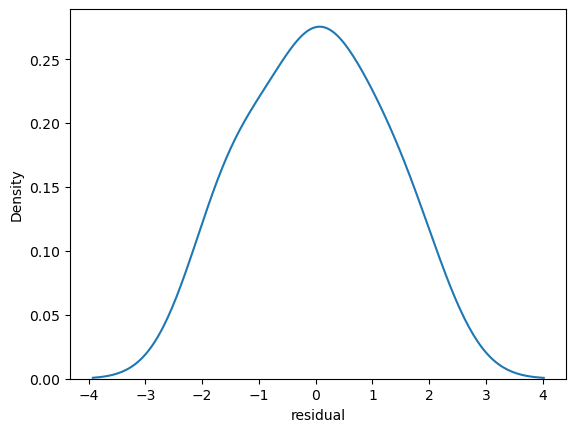

In [34]:
sns.kdeplot(quartet['residual'])

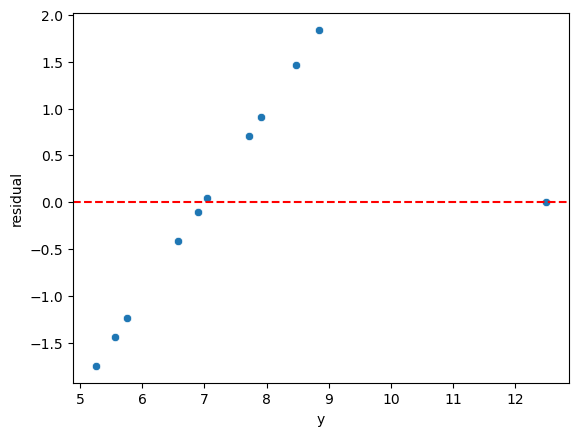

In [35]:
sns.scatterplot(data=quartet,x='y',y='residual')
plt.axhline(y=0, color='r', linestyle='--')

## Onderzoek of onze dataset met sales in functie van advertenties geschikt was voor ons lineaire regressiemodel

In [36]:
# Bepaal de residuals op basis van de voorspellingen op de test set
test_residuals = y_test - test_predictions

In [37]:
test_residuals

37    -1.041313
109    0.189374
31     0.451111
89    -0.308198
66     0.327143
119   -0.412483
54    -0.089925
74    -0.299540
145    0.524155
142    0.878058
148   -1.505032
112    0.207650
174   -2.225411
55     2.412060
141    0.775434
149    0.118016
25    -3.552290
34     1.810863
170    0.843850
39     1.096888
172   -0.192152
153    0.757859
175    2.313681
61     1.378009
65     1.320379
50    -1.252073
42    -0.769259
129    1.647714
179    0.176840
2     -3.207197
12    -1.577578
133    0.355399
90     1.129731
22    -1.107800
41    -0.214921
32     1.832357
125    1.346067
196    1.421653
158   -3.281056
180   -0.135911
16    -0.510026
186    0.528079
144    1.185301
121   -1.045720
80     0.232893
18     1.216320
78    -3.698066
48    -1.453889
4     -0.339423
15     1.585066
1     -2.097274
43    -1.066159
102   -2.762851
164    0.754630
9     -1.962615
155   -2.308703
36     2.105349
190   -1.824097
33    -1.374000
45    -0.287857
Name: sales, dtype: float64

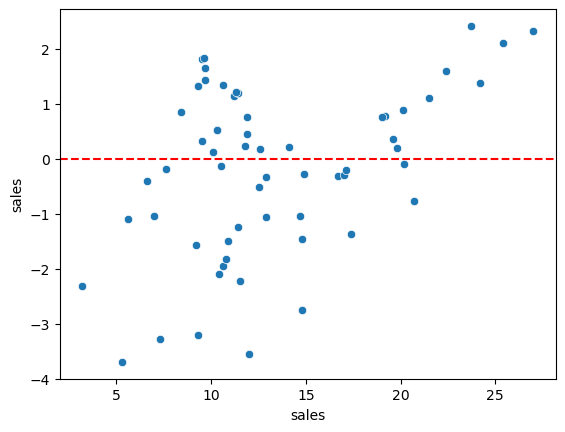

In [38]:
# Plot de residuals tov de testwaarden
sns.scatterplot(x=y_test,y=test_residuals)
plt.axhline(y=0, color='r', linestyle='--')

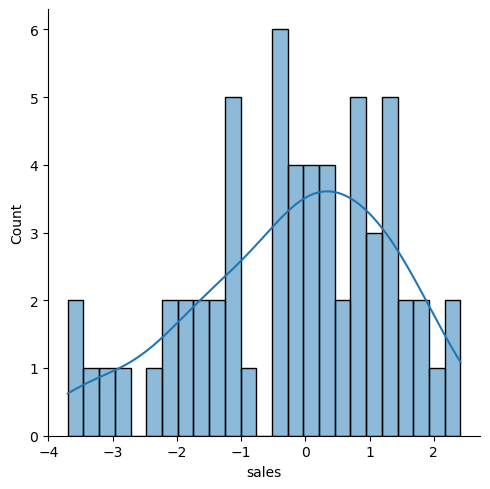

In [39]:
# Maak een distributieplot van de residuals op de test set
sns.displot(test_residuals,bins=25,kde=True)

**Gemiddelde rond nul?**

residual = y - ŷ.  De "left tail" (left skewed) betekent dat we een beetje "overshooten" met ons model.

In [40]:
## Onzeker of dit normaal is verdeeld?  We kunnen dit aftoetsen tegenover een normal probability plot.  Deze geeft  
import scipy as sp

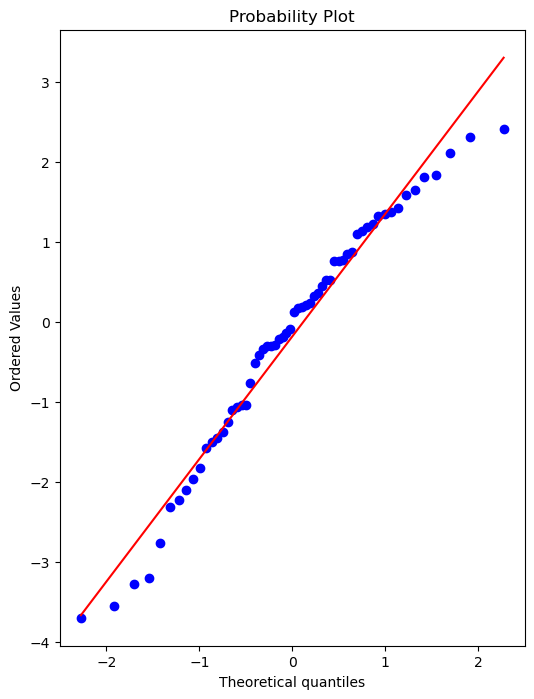

In [41]:
# Create a figure and axis to plot on
fig, ax = plt.subplots(figsize=(6,8),dpi=100)
# probplot returns the raw values if needed
# we just want to see the plot, so we assign these values to _
_ = sp.stats.probplot(test_residuals,plot=ax)

# Deployen van het model

## Trainen van het model op de volledige dataset

## Opslaan en opnieuw laden van een model

In [42]:
# Nieuwe modelinstance maken:
final_model = LinearRegression()

In [43]:
# Fitten van het model op alle data:
final_model.fit(X,y)

LinearRegression()

Aangezien het model alle data heeft gezien, heeft het weinig zin om vb RMSE te herberekenen - we moeten ons baseren op de waarden die we voorheen hebben berekend!

In [44]:
# Coëfficiënten van het model
final_model.coef_

array([ 0.04576465,  0.18853002, -0.00103749])

In [45]:
X.head()

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


## Plot voorspellingen tov echte y labels

In [46]:
y_hat = final_model.predict(X)

Text(0.5, 1.0, 'Newspaper Spend')

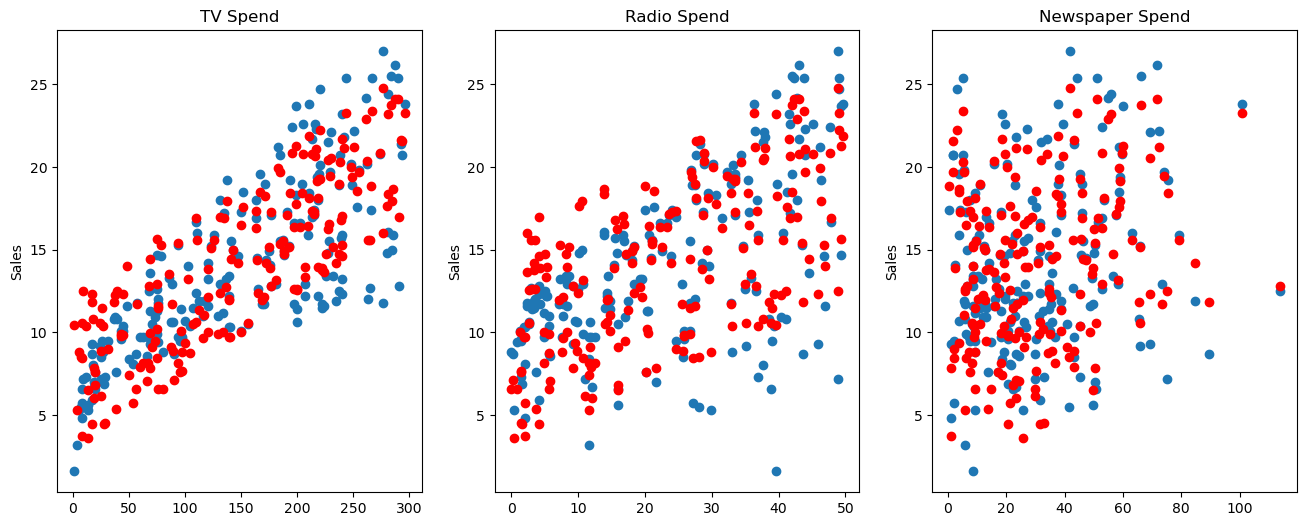

In [47]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,6))

# plot TV vs Sales - de "echte" y labels
axes[0].plot(df['TV'], df['sales'],'o')
# plot de voorspelde sales
axes[0].plot(df['TV'], y_hat,'o', color='red')
axes[0].set_ylabel("Sales")
axes[0].set_title("TV Spend")

# plot radio vs Sales
axes[1].plot(df['radio'], df['sales'],'o')
axes[1].plot(df['radio'], y_hat,'o', color='red')
axes[1].set_ylabel("Sales")
axes[1].set_title("Radio Spend")

# plot newspaper vs Sales
axes[2].plot(df['newspaper'], df['sales'],'o')
axes[2].plot(df['newspaper'], y_hat,'o', color='red')
axes[2].set_ylabel("Sales")
axes[2].set_title("Newspaper Spend")

In [48]:
# saven en opnieuw laden van het model

In [49]:
from joblib import dump, load

In [50]:
dump(final_model, 'final_sales_model.joblib')

['final_sales_model.joblib']

In [51]:
loaded_model = load('final_sales_model.joblib')

In [52]:
loaded_model.coef_

array([ 0.04576465,  0.18853002, -0.00103749])

### Finale test: voorspellen van de sales waarde voor een nieuwe campagne

In [53]:
X.shape

(200, 3)

In [54]:
# voorspel de sales voor een campagne met 149 TV,  
# 22 radio, en 12 newspaper
# maak een dataframe voor het nieuwe datapunt
campaign = [[149, 22, 12]]
columns = ['TV', 'radio', 'newspaper']
new_datapoint = pd.DataFrame(campaign, columns=columns)
1}

In [57]:
loaded_model.predict(new_datapoint)

array([13.893032])